# Food delivery time: from a prediction to a promise

A delivery app has to tell every customer how long they will wait. Promise too little and orders
arrive late; promise too much and customers leave before ordering. This notebook:

1. audits the data and finds a duplicates problem that would have inflated the results,
2. compares models with cross-validation that does not leak,
3. shows where the model is wrong and what drives delivery time,
4. turns predictions into a **promised delivery time** that keeps 90% of orders on time
   with the shortest possible wait.

**Data:** the delivery dataset from the KAUST Academy AI program (Kaggle: `mohammad2012191/q1-ka-ai-2026`).
It is a modified copy of a public Kaggle dataset of 1,000 orders: the KAUST version adds duplicate
rows and extra missing values, which is what makes the cleaning step matter. Metric throughout: **mean absolute error (MAE) in minutes**.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, KFold, RepeatedKFold

sys.path.insert(0, str(Path.cwd().parent / "src"))
from delivery_eta import data, modeling, plots

pd.set_option("display.precision", 2)
FIGURES = Path("../reports/figures")
DATA_DIR = Path("../data")
DATA_FILE = DATA_DIR / "Q1_data.csv"

raw = data.load_raw(DATA_FILE)
print(f"Loaded {DATA_FILE.name}: {raw.shape[0]:,} rows, {raw.shape[1]} columns")
display(raw.head())

Loaded Q1_data.csv: 1,663 rows, 9 columns


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.00,43.00
1,738,16.42,Clear,Medium,Evening,Bike,20,2.00,84.00
2,741,9.52,Foggy,Low,Night,Scooter,28,1.00,59.00
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.00,37.00
4,412,19.03,Clear,Low,Morning,Bike,16,5.00,68.00


## 1. Data audit

In [2]:
display(data.audit(raw))
dups = data.duplicate_report(raw)
display(pd.Series(dups, name="count").to_frame())
print("Order IDs whose copies disagree on a value:", data.conflicting_copies(raw))

,dtype,missing,missing_%,distinct
Delivery_Time,float64,106,6.40,108
Weather,str,55,3.30,5
Traffic_Level,str,51,3.10,3
Time_of_Day,str,50,3.00,4
Courier_Experience_yrs,float64,49,2.90,10
Order_ID,int64,0,0.00,1000
Distance_km,float64,0,0.00,785
Preparation_Time_min,int64,0,0.00,25
Vehicle_Type,str,0,0.00,3


,count
rows,1663
unique_orders,1000
exact_duplicate_rows,557
rows_sharing_an_order_id,663
order_ids_repeated,663


Order IDs whose copies disagree on a value: 0


After merging copies of the same order and dropping unlabelled orders: 1,000 orders
Delivery time: average 56.7 min, median 56 min, range 8-153 min


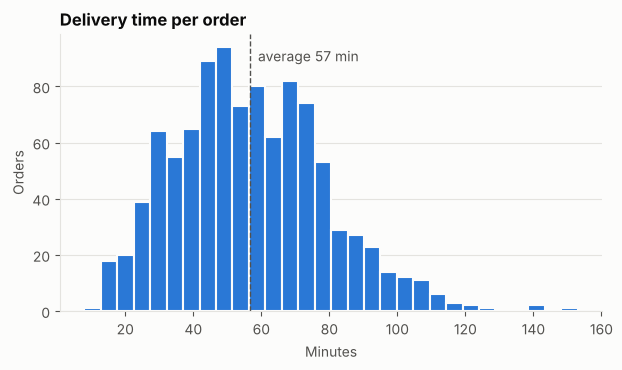

In [3]:
df = data.clean(raw)
X, y = df[data.FEATURES], df[data.TARGET]
print(f"After merging copies of the same order and dropping unlabelled orders: {len(df):,} orders")
print(f"Delivery time: average {y.mean():.1f} min, median {y.median():.0f} min, range {y.min():.0f}-{y.max():.0f} min")

fig = plots.target_distribution(y)
plots.save(fig, FIGURES / "target_distribution.png")

**What the audit found.** The file has 1,663 rows but only 1,000 distinct orders. 557 rows are exact
copies, and another 106 are copies of an order with one value blanked out. No two copies of the same
order disagree on any value, so each order's copies can safely be merged into one row, filling a
blank in one copy from another. That recovers all 106 missing delivery times and 85 blanked feature
values instead of dropping or guessing them. 30 gaps remain in each of Weather, Traffic_Level,
Time_of_Day and Courier_Experience_yrs; the pipeline handles those inside each fold.

Delivery times average 56.7 minutes, with a long right tail up to 153 minutes.

## 2. How much would the duplicates have flattered the score?

If copies of the same order land in both the training and the test fold, the model is tested on
orders it has already seen. Three setups, same Random Forest:

- **Plain K-fold on the raw rows**: copies can be split across folds (what a quick notebook does).
- **Group K-fold on the raw rows**: all copies of an order stay in the same fold.
- **K-fold on the cleaned data**: one row per order (the setup used from here on).

,setup,MAE_min
0,"Plain K-fold, raw rows (leaky)",5.42
1,"Group K-fold, raw rows",7.68
2,"K-fold, cleaned data",7.53


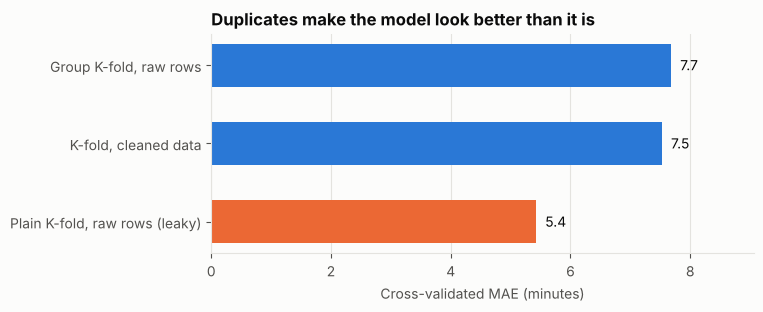

In [4]:
labelled = raw.dropna(subset=[data.TARGET]).reset_index(drop=True)
rf = modeling.make_models()["Random forest"]

if dups["rows_sharing_an_order_id"] == 0:
    print("No repeated orders in this file, so there is nothing to leak.")
    leak = None
else:
    Xr, yr, groups = labelled[data.FEATURES], labelled[data.TARGET], labelled[data.ID_COL]
    kf = KFold(n_splits=5, shuffle=True, random_state=modeling.SEED)
    leak = pd.DataFrame({
        "setup": ["Plain K-fold, raw rows (leaky)", "Group K-fold, raw rows", "K-fold, cleaned data"],
        "MAE_min": [
            modeling.cv_scores(rf, Xr, yr, kf).mean(),
            modeling.cv_scores(rf, Xr, yr, GroupKFold(n_splits=5), groups=groups).mean(),
            modeling.cv_scores(rf, X, y, kf).mean(),
        ],
    })
    display(leak)
    fig = plots.hbar(leak.set_index("setup")["MAE_min"], "Duplicates make the model look better than it is",
                     "Cross-validated MAE (minutes)", highlight="Plain K-fold, raw rows (leaky)")
    plots.save(fig, FIGURES / "leak_test.png")

With copies split across folds, the Random Forest scores **5.4 minutes**. Keep each order's copies
in the same fold and the same model on the same rows scores **7.7 minutes**; on the cleaned data it
scores **7.5**. The duplicates make the model look about **28% better than it is**, because it is
tested on orders it has already memorised. Every score from here on uses the cleaned data.

## 3. Model comparison

Every model is a single scikit-learn pipeline (impute → one-hot encode → model) fitted inside each
fold, so the test fold never influences the imputation. Five-fold cross-validation repeated three
times; the table shows the mean MAE and its spread across the 15 folds. The baseline always
predicts the training average, so every other model has a number to beat.

,model,MAE_min,MAE_std
0,Linear regression,6.61,0.51
1,RF + GB average,7.46,0.34
2,Random forest,7.53,0.38
3,Gradient boosting,7.84,0.37
4,Baseline (always the average),17.82,0.52


Best model: Linear regression, MAE 6.61 min (63% lower than the baseline's 17.82 min)


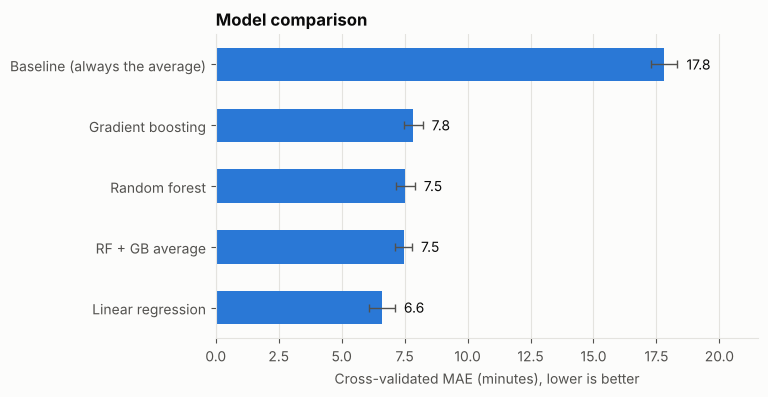

In [5]:
models = modeling.make_models()
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=modeling.SEED)
results = modeling.compare_models(models, X, y, cv)
display(results)

fig = plots.hbar(results.set_index("model")["MAE_min"], "Model comparison",
                 "Cross-validated MAE (minutes), lower is better",
                 errors=results.set_index("model")["MAE_std"])
plots.save(fig, FIGURES / "model_comparison.png")

best_name = results.loc[results["model"] != "Baseline (always the average)", "model"].iloc[0]
best = models[best_name]
baseline_mae = results.set_index("model").loc["Baseline (always the average)", "MAE_min"]
best_mae = results.set_index("model").loc[best_name, "MAE_min"]
print(f"Best model: {best_name}, MAE {best_mae:.2f} min "
      f"({100 * (1 - best_mae / baseline_mae):.0f}% lower than the baseline's {baseline_mae:.2f} min)")

**Plain linear regression wins at 6.6 minutes**, 63% below the baseline's 17.8 and about 0.9 minutes
better than the Random Forest (7.5) used in the original exam solution. The tree models and their
average all land between 7.5 and 7.8. With only 1,000 orders and a relationship that is mostly
additive (more distance, more preparation, worse traffic: each adds time), the flexible models spend
their capacity fitting noise. The simplest model is the right call here, and it is also the easiest
to explain to an operations team.

## 4. Where the model is wrong

Out-of-fold MAE for Linear regression: 6.62 min
Orders predicted within 5 minutes: 56%


,orders,avg_actual_min,MAE_min
Traffic_Level,,,
Unknown,30,62.07,7.88
High,197,64.81,7.08
Low,383,52.89,6.61
Medium,390,56.02,6.30


,orders,avg_actual_min,MAE_min
Weather,,,
Unknown,30,54.20,8.71
Foggy,103,59.47,8.01
Rainy,204,59.79,7.47
Snowy,97,67.11,6.93
Clear,470,53.08,6.07
Windy,96,55.46,5.05


,orders,avg_actual_min,MAE_min
Vehicle_Type,,,
Car,195,58.20,7.02
Bike,503,56.57,6.75
Scooter,302,56.05,6.15


,orders,avg_actual_min,MAE_min
Time_of_Day,,,
Unknown,30,66.17,14.12
Night,85,55.21,7.24
Evening,293,57.48,7.11
Morning,308,56.12,5.95
Afternoon,284,56.08,5.86


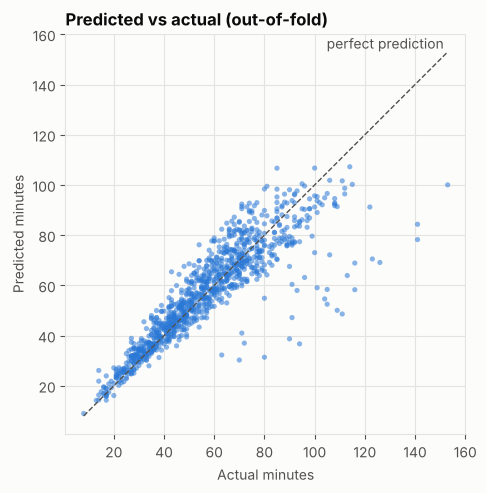

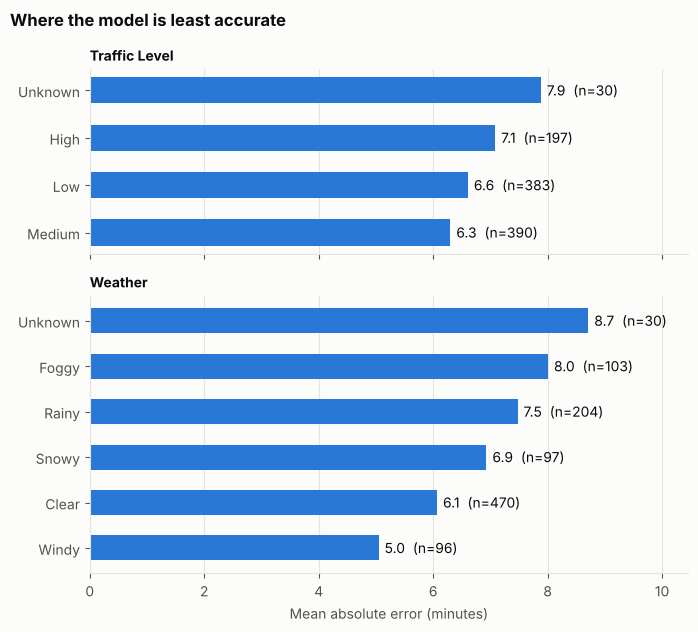

In [6]:
oof = modeling.oof_predictions(best, X, y)
print(f"Out-of-fold MAE for {best_name}: {(y - oof).abs().mean():.2f} min")
print(f"Orders predicted within 5 minutes: {100 * ((y - oof).abs() <= 5).mean():.0f}%")

fig = plots.predicted_vs_actual(y, oof)
plots.save(fig, FIGURES / "predicted_vs_actual.png")

segments = {col: modeling.error_by_segment(df, y, oof, col)
            for col in ["Traffic_Level", "Weather", "Vehicle_Type", "Time_of_Day"]}
for col, table in segments.items():
    display(table)
fig = plots.error_by_segments({c: segments[c] for c in ["Traffic_Level", "Weather"]})
plots.save(fig, FIGURES / "error_by_segment.png")

Half of the orders are predicted within about 4.4 minutes (56% within 5 minutes), but the error has
a long tail: 3.5% of orders are off by more than 20 minutes and the worst misses are 50 to 63
minutes. Those are very long deliveries that nothing in the data explains.

Errors are larger in fog (8.0 min) and rain (7.5) than in clear weather (6.1), and larger in high
traffic (7.1) than in medium (6.3): the conditions that add delay also add uncertainty. Orders with
a missing time of day show the largest error (14.1 min), but that is only 30 orders and two misses
of 53 and 63 minutes drive it (their median error is 8.5 minutes).

## 5. What drives delivery time

Permutation importance: shuffle one column on the held-out fold and measure how much the MAE rises.
It is computed on the original columns (before one-hot encoding), so each bar is a feature a person
recognises, and averaged over five folds.

,feature,MAE_increase_min,std
0,Distance_km,14.52,0.31
1,Preparation_Time_min,4.16,0.20
2,Traffic_Level,1.99,0.32
3,Weather,1.16,0.17
4,Courier_Experience_yrs,0.40,0.08
5,Time_of_Day,0.04,0.11
6,Vehicle_Type,0.02,0.02


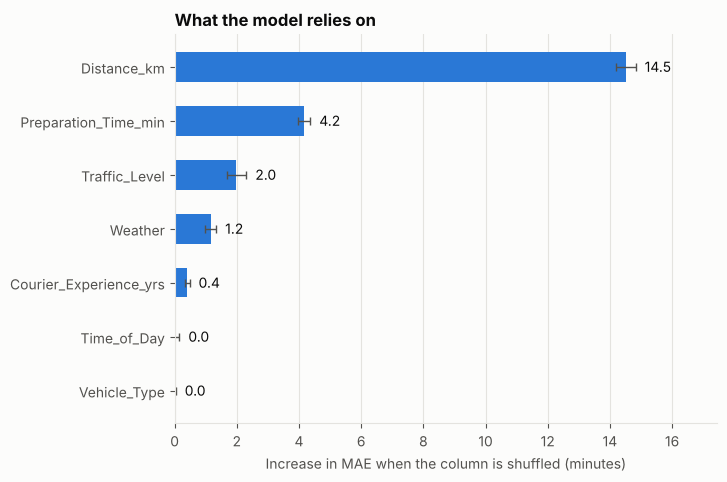

In [7]:
importance = modeling.grouped_permutation_importance(best, X, y)
display(importance)
fig = plots.hbar(importance.set_index("feature")["MAE_increase_min"],
                 "What the model relies on", "Increase in MAE when the column is shuffled (minutes)",
                 errors=importance.set_index("feature")["std"])
plots.save(fig, FIGURES / "feature_importance.png")

In [8]:
# The winning model is linear, so its coefficients read directly in minutes.
final_model = clone(best).fit(X, y)
if hasattr(final_model.named_steps["model"], "coef_"):
    effects = modeling.linear_effects(final_model)
    display(effects.round(2).to_frame("minutes"))
    print(f"Each extra km adds {effects['Distance_km']:.1f} min; each minute of preparation adds "
          f"{effects['Preparation_Time_min']:.1f} min.")
    print(f"High vs low traffic: +{effects['Traffic_Level_High'] - effects['Traffic_Level_Low']:.1f} min. "
          f"Snowy vs clear: +{effects['Weather_Snowy'] - effects['Weather_Clear']:.1f} min. "
          f"Foggy vs clear: +{effects['Weather_Foggy'] - effects['Weather_Clear']:.1f} min.")

,minutes
Distance_km,2.99
Preparation_Time_min,0.97
Courier_Experience_yrs,-0.62
Weather_Clear,-4.90
Weather_Foggy,2.87
Weather_Rainy,0.29
Weather_Snowy,4.68
Weather_Unknown,-0.05
Weather_Windy,-2.89
Traffic_Level_High,5.71


Each extra km adds 3.0 min; each minute of preparation adds 1.0 min.
High vs low traffic: +12.1 min. Snowy vs clear: +9.6 min. Foggy vs clear: +7.8 min.


Distance dominates: shuffling it raises the error by 14.5 minutes. Preparation time (4.2), traffic
(2.0) and weather (1.2) follow; courier experience matters a little (0.4); time of day and vehicle
type add nothing the other columns don't already carry.

In the linear model's own units: each extra kilometre adds about 3.0 minutes, each minute of
preparation about 1.0 minute, high traffic about 12 minutes compared with low, and snow about 9.6
minutes compared with clear weather.

## 6. From a number to a promise

A point prediction is right on average, so roughly half the orders would arrive after it. The app
needs a promise that holds for most orders. Target: **90% of orders on time**. Three strategies:

- **Same promise for every order**: one number for everyone (what an app without a model does).
- **Point estimate + flat buffer**: the best model's prediction plus a fixed number of minutes.
- **Quantile model**: a linear model trained directly on the 90th percentile (quantile regression),
  so each order gets its own margin.

All three are calibrated the same way: inside each training fold, find the offset that would have
put 90% of the training orders on time (using out-of-fold predictions, never in-sample ones), then
apply it to the untouched test fold. The comparison is fair: same target, judged on orders no model
or offset ever saw. The winner is the strategy that reaches the target with the shortest promise.

,strategy,on_time_%,avg_promised_min,median_min_late_when_late
0,Same promise for every order,89.80,86.05,8.88
1,Point estimate + flat buffer,90.10,65.93,4.91
2,Quantile model (90th percentile),89.40,64.98,1.42


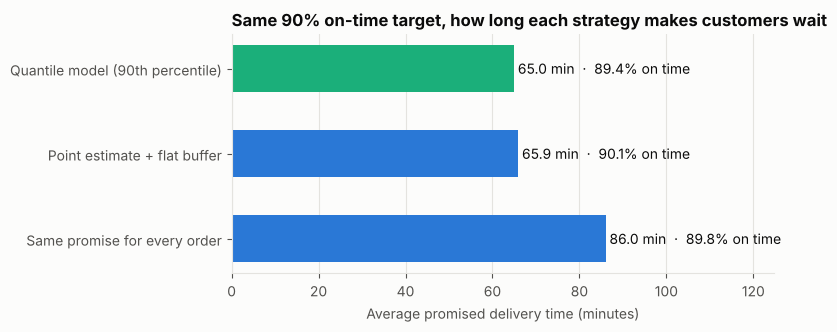

In [9]:
promise_models = modeling.promise_models(best)
promises = {name: modeling.calibrated_promises(m, X, y, target=0.9) for name, m in promise_models.items()}
report = modeling.promise_report(y, promises)
display(report)

fig = plots.promise_tradeoff(report)
plots.save(fig, FIGURES / "promise_tradeoff.png")

All three strategies land at about 90% on time, judged on orders they never saw. The difference is
the wait. One promise for every order has to be about **86 minutes**, because it must cover long
trips even when the trip is short. With the model, the promise drops to about **65-66 minutes**:
that is **about 20 minutes (23%) shorter** for the customer at the same reliability.

The two model-based options are close. The flat buffer is the prediction plus about 9 minutes. The
quantile model gives each order its own margin: its promise is about a minute shorter, and when it
misses, it misses by a median of 1.4 minutes instead of 4.9. Its on-time rate is 0.7 points lower
(89.4% vs 90.1%), which is about 7 orders out of 1,000.

## 7. Conclusions

**Recommendation:** set the promise with the 90th-percentile quantile model, shown to the customer
as a window from the point prediction to the promise (for example "50-58 min"). Keep *prediction +
9 minutes* as the simple fallback. Recalibrate monthly and track the on-time rate.

- **Check for duplicates before cross-validation.** Here they would have overstated accuracy by 28%.
- **Start simple.** Linear regression beat both tree ensembles and their average.
- **The business value is in the promise, not the decimal.** The model's real payoff is a promise
  about 20 minutes shorter at the same 90% on-time rate.

**Limitations.** 1,000 orders from a public practice dataset with no dates, locations or restaurant
details, so this shows the method rather than a production-ready number. The long tail of very late
orders is not explained by the available columns. Calibration assumes future orders look like these.

**Next steps.** Add live signals (traffic, restaurant load, courier position), check whether a margin
that grows in fog, rain and heavy traffic helps further, and monitor the on-time rate after launch.